In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [2]:
sns.set_theme(style="whitegrid")

cohort_path = Path(
    "../data/processed/readmission_cohort.csv"
)

df = pd.read_csv(cohort_path)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())
df.info()

Rows: 101766
Columns: 23


,encounter_id,patient_nbr,race,gender,age,time_in_hospital,admission_type_id,discharge_disposition_id,admission_source_id,num_lab_procedures,...,number_emergency,number_inpatient,number_diagnoses,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,readmitted,target_readmission_30d
0,2278392,8222157,Caucasian,Female,[0-10),1,6,25,1,41,...,0,0,1,250.83,?,?,NaN,NaN,NO,0
1,149190,55629189,Caucasian,Female,[10-20),3,1,1,7,59,...,0,0,9,276,250.01,255,NaN,NaN,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),2,1,1,7,11,...,0,1,6,648,250,V27,NaN,NaN,NO,0
3,500364,82442376,Caucasian,Male,[30-40),2,1,1,7,44,...,0,0,7,8,250.43,403,NaN,NaN,NO,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,1,7,51,...,0,0,5,197,157,250,NaN,NaN,NO,0


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 23 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   time_in_hospital          101766 non-null  int64
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   num_lab_procedures        101766 non-null  int64
 10  num_procedures            101766 non-null  int64
 11  num_medications           101766 non-null  int64
 12  number_outpatient         101766 non-null  int64
 13  number_emergency          101766 non-null  int64
 14  number_inpatient          10176

Check that the target exists and contains only the expected binary values

In [4]:
# Verified: 'df' is now properly loaded from the processed CSV path
assert "target_readmission_30d" in df.columns

print("--- Absolute Counts ---")
print(df["target_readmission_30d"].value_counts(dropna=False))

print("\n--- Class Proportions ---")
print(df["target_readmission_30d"].value_counts(normalize=True))




--- Absolute Counts ---
target_readmission_30d
0    90409
1    11357
Name: count, dtype: int64

--- Class Proportions ---
target_readmission_30d
0    0.888401
1    0.111599
Name: proportion, dtype: float64


Clean missing values and duplicates

In [5]:
df = df.replace(
    ["?", "Unknown/Invalid", ""],
    np.nan
)

# Remove duplicate encounters, if any.
print("Duplicate encounter IDs before cleaning:",
      df["encounter_id"].duplicated().sum())

df = df.drop_duplicates(subset=["encounter_id"]).copy()

print("Shape after duplicate removal:", df.shape)

Duplicate encounter IDs before cleaning: 0
Shape after duplicate removal: (101766, 23)


Convert numeric columns to numeric types:

In [7]:
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "target_readmission_30d"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_cols].dtypes)

time_in_hospital            int64
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
number_outpatient           int64
number_emergency            int64
number_inpatient            int64
number_diagnoses            int64
admission_type_id           int64
discharge_disposition_id    int64
admission_source_id         int64
target_readmission_30d      int64
dtype: object


Missing-value analysis

In [8]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary.head(20))

,missing_count,missing_percent
max_glu_serum,96420,94.75
a1cresult,84748,83.28
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
encounter_id,0,0.00
admission_type_id,0,0.00
time_in_hospital,0,0.00
age,0,0.00


Visualize the top 15 fields by missingness:

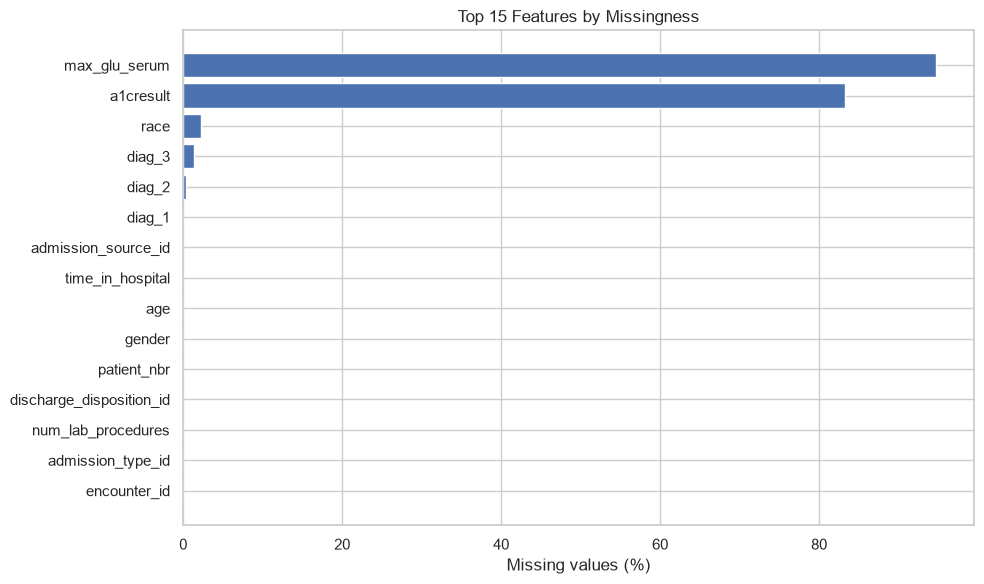

In [9]:
missing_top = missing_summary.head(15).sort_values("missing_percent")

plt.figure(figsize=(10, 6))
plt.barh(missing_top.index, missing_top["missing_percent"])
plt.xlabel("Missing values (%)")
plt.title("Top 15 Features by Missingness")
plt.tight_layout()
plt.show()

Explore the patient population

Readmission class distribution

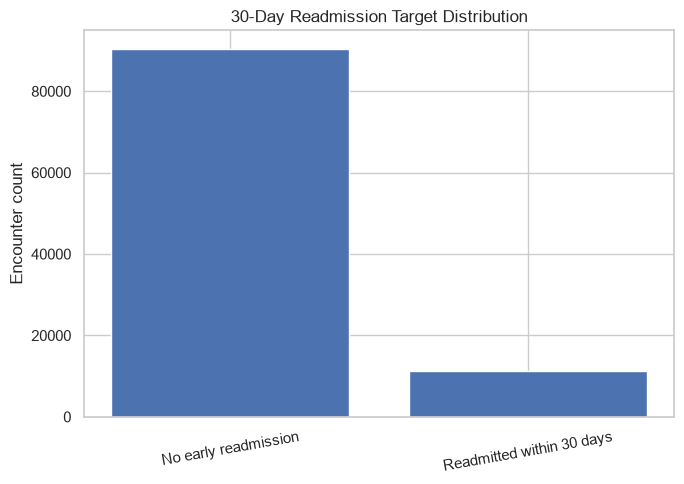

In [10]:
target_counts = df["target_readmission_30d"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No early readmission", "Readmitted within 30 days"],
    [target_counts.get(0, 0), target_counts.get(1, 0)]
)
plt.ylabel("Encounter count")
plt.title("30-Day Readmission Target Distribution")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

Age group distribution

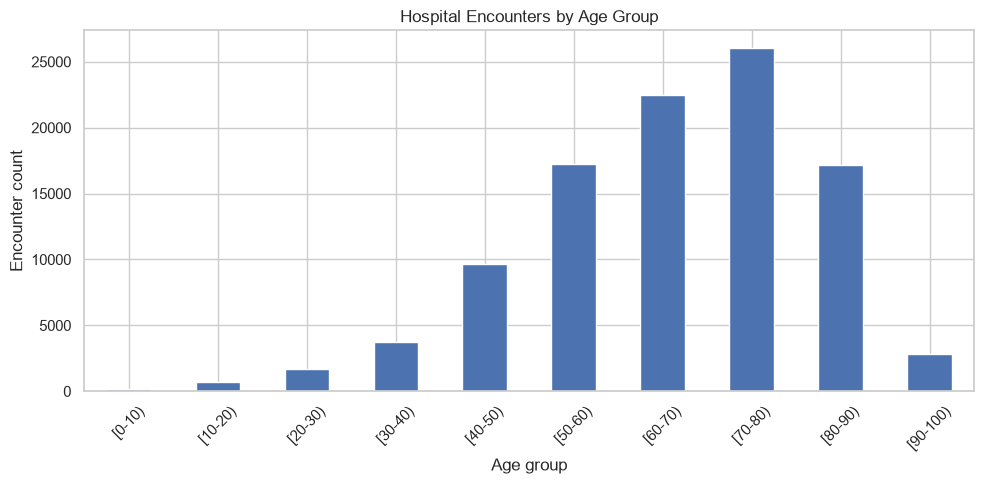

In [11]:
age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)",
    "[40-50)", "[50-60)", "[60-70)", "[70-80)",
    "[80-90)", "[90-100)"
]

if "age" in df.columns:
    age_counts = df["age"].value_counts().reindex(age_order)

    plt.figure(figsize=(10, 5))
    age_counts.plot(kind="bar")
    plt.ylabel("Encounter count")
    plt.xlabel("Age group")
    plt.title("Hospital Encounters by Age Group")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Length of stay distribution

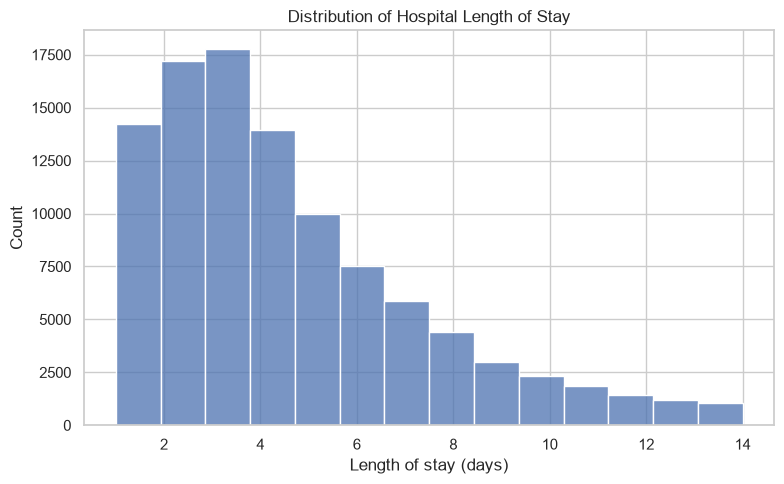

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="time_in_hospital",
    bins=14,
    kde=False
)
plt.title("Distribution of Hospital Length of Stay")
plt.xlabel("Length of stay (days)")
plt.tight_layout()
plt.show()

Length of stay by readmission outcome

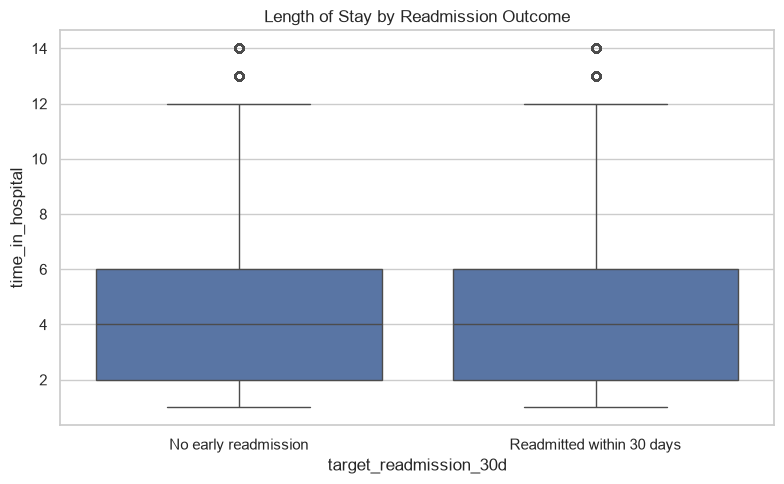

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="target_readmission_30d",
    y="time_in_hospital"
)
plt.xticks([0, 1], ["No early readmission", "Readmitted within 30 days"])
plt.title("Length of Stay by Readmission Outcome")
plt.tight_layout()
plt.show()

Readmission rate by age group

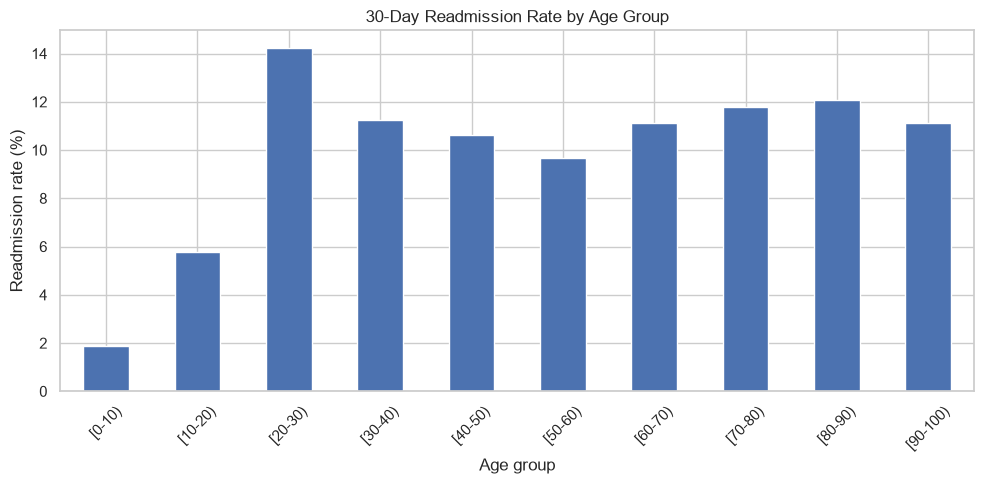

In [14]:
readmission_by_age = (
    df.groupby("age", observed=True)["target_readmission_30d"]
      .mean()
      .mul(100)
      .reindex(age_order)
)

plt.figure(figsize=(10, 5))
readmission_by_age.plot(kind="bar")
plt.ylabel("Readmission rate (%)")
plt.xlabel("Age group")
plt.title("30-Day Readmission Rate by Age Group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation heatmap

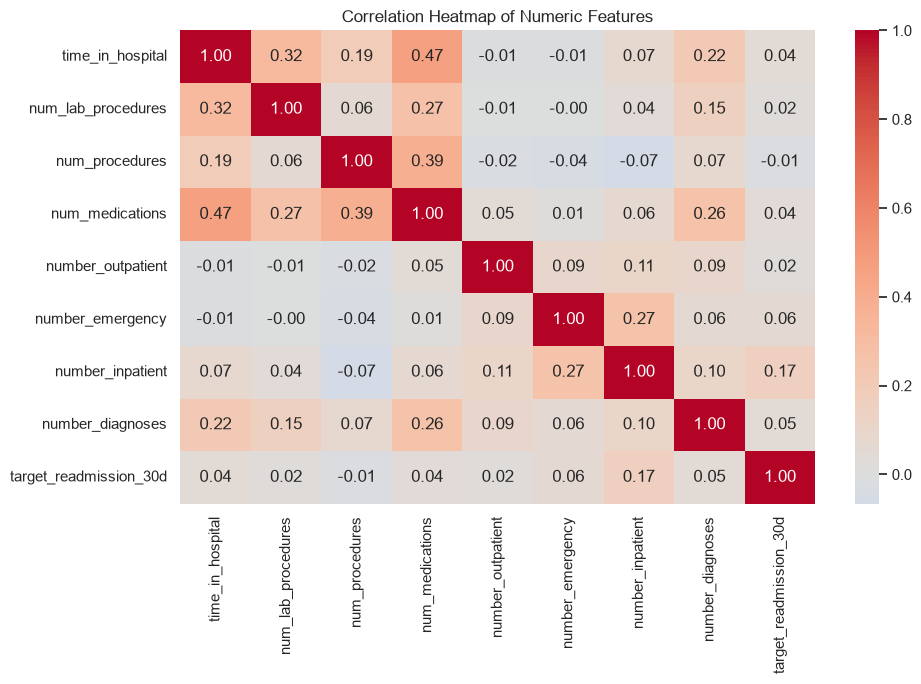

In [15]:
corr_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "target_readmission_30d"
]

corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

Feature engineering for clinical risk analysis

In [16]:
utilization_cols = [
    "number_inpatient",
    "number_emergency",
    "number_outpatient"
]

df["prior_utilization_total"] = (
    df[utilization_cols].fillna(0).sum(axis=1)
)

df["multiple_prior_inpatient_visits"] = (
    df["number_inpatient"].fillna(0) >= 2
).astype(int)

display(
    df[
        utilization_cols
        + ["prior_utilization_total", "multiple_prior_inpatient_visits"]
    ].head()
)

,number_inpatient,number_emergency,number_outpatient,prior_utilization_total,multiple_prior_inpatient_visits
0,0,0,0,0,0
1,0,0,0,0,0
2,1,0,2,3,0
3,0,0,0,0,0
4,0,0,0,0,0


Feature 2 — Group diagnosis codes

In [18]:
def diagnosis_group(code):
    if pd.isna(code):
        return "Missing"

    code = str(code).strip().upper()

    if code.startswith("V"):
        return "Supplementary / V codes"
    if code.startswith("E"):
        return "External causes"

    try:
        number = float(code)
    except ValueError:
        return "Other / unclassified"

    if 390 <= number <= 459 or number == 785:
        return "Circulatory"
    elif 250 <= number < 251:
        return "Diabetes"
    elif 460 <= number <= 519 or number == 786:
        return "Respiratory"
    elif 520 <= number <= 579 or number == 787:
        return "Digestive"
    elif 800 <= number <= 999:
        return "Injury / poisoning"
    else:
        return "Other diagnosis"

df["primary_diagnosis_group"] = df["diag_1"].apply(diagnosis_group)

display(df["primary_diagnosis_group"].value_counts())

primary_diagnosis_group
Circulatory                30437
Other diagnosis            30034
Respiratory                14423
Digestive                   9475
Diabetes                    8757
Injury / poisoning          6974
Supplementary / V codes     1644
Missing                       21
External causes                1
Name: count, dtype: int64

Readmission rate by primary diagnosis group

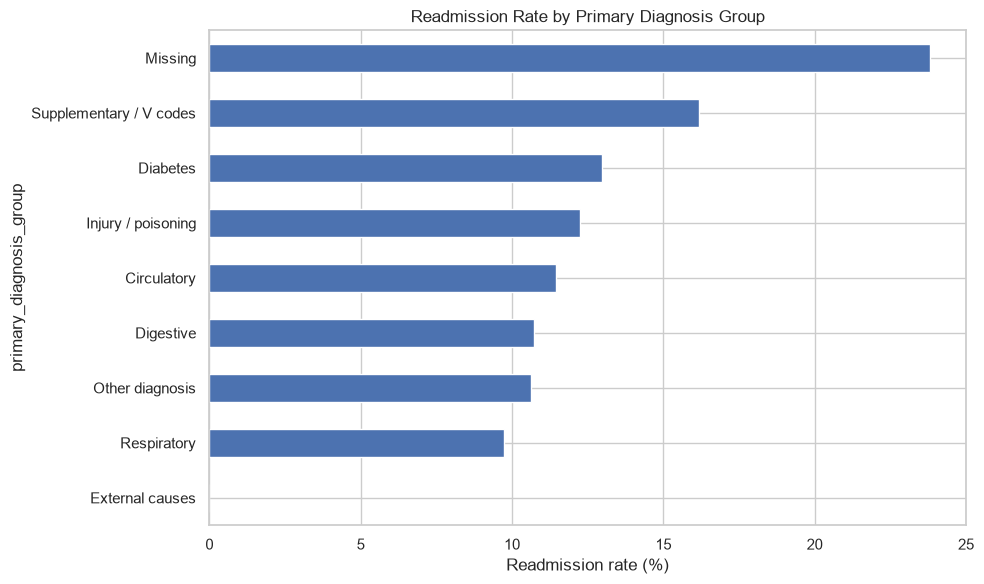

,mean,count,readmission_rate_pct
primary_diagnosis_group,,,
Missing,0.238095,21,23.809524
Supplementary / V codes,0.161800,1644,16.180049
Diabetes,0.129839,8757,12.983899
Injury / poisoning,0.122455,6974,12.245483
Circulatory,0.114499,30437,11.449880
Digestive,0.107124,9475,10.712401
Other diagnosis,0.106280,30034,10.627955
Respiratory,0.097275,14423,9.727519
External causes,0.000000,1,0.000000


In [19]:
diagnosis_rates = (
    df.groupby("primary_diagnosis_group")["target_readmission_30d"]
      .agg(["mean", "count"])
      .sort_values("mean", ascending=False)
)

diagnosis_rates["readmission_rate_pct"] = diagnosis_rates["mean"] * 100

plt.figure(figsize=(10, 6))
diagnosis_rates["readmission_rate_pct"].sort_values().plot(kind="barh")
plt.xlabel("Readmission rate (%)")
plt.title("Readmission Rate by Primary Diagnosis Group")
plt.tight_layout()
plt.show()

display(diagnosis_rates)

Feature 3 — Patient risk segmentation

In [21]:
df["utilization_segment"] = pd.cut(
    df["number_inpatient"],
    bins=[-np.inf, 0, 1, np.inf],
    labels=[
        "No prior inpatient visits",
        "One prior inpatient visit",
        "Two or more prior inpatient visits"
    ]
)

segment_summary = (
    df.groupby("utilization_segment", observed=False)
      .agg(
          encounters=("encounter_id", "count"),
          readmission_rate=("target_readmission_30d", "mean")
      )
      .reset_index()
)

segment_summary["readmission_rate_pct"] = (
    segment_summary["readmission_rate"] * 100
)

display(segment_summary)

,utilization_segment,encounters,readmission_rate,readmission_rate_pct
0,No prior inpatient visits,67630,0.084371,8.437084
1,One prior inpatient visit,19521,0.129245,12.924543
2,Two or more prior inpatient visits,14615,0.214027,21.402668


Calculate the initial project KPIs

In [22]:
total_encounters = len(df)
positive_encounters = int(df["target_readmission_30d"].sum())

readmission_rate = (
    positive_encounters / total_encounters * 100
    if total_encounters else np.nan
)

average_length_of_stay = df["time_in_hospital"].mean()

print(f"Total encounters: {total_encounters:,}")
print(f"Early readmissions: {positive_encounters:,}")
print(f"Early readmission rate: {readmission_rate:.2f}%")
print(f"Average length of stay: {average_length_of_stay:.2f} days")

Total encounters: 101,766
Early readmissions: 11,357
Early readmission rate: 11.16%
Average length of stay: 4.40 days


Save the cleaned dataset for the next stage

In [23]:
processed_dir = Path("../data/processed") 

cleaned_path = processed_dir / "readmission_cleaned_eda.csv"
df.to_csv(cleaned_path, index=False)

print("Saved:", cleaned_path.resolve())
print("Final dataset shape:", df.shape)

Saved: C:\Users\Ranjana\patient_readmission_risk_rediction\data\processed\readmission_cleaned_eda.csv
Final dataset shape: (101766, 27)


In [39]:
import os
from pathlib import Path

# Print out exactly where your script is saving files
processed_dir = Path("./data/processed").resolve()
print("📂 Your files are being saved to this exact folder path:")
print(processed_dir)

print("\n🔍 Is the directory physically there?:", processed_dir.exists())

if processed_dir.exists():
    print("\n📄 Files currently inside that folder:")
    print(os.listdir(processed_dir))


📂 Your files are being saved to this exact folder path:
C:\Users\Ranjana\patient_readmission_risk_rediction\notebooks\data\processed

🔍 Is the directory physically there?: True

📄 Files currently inside that folder:
['readmission_cleaned_eda.csv', 'readmission_cohort.csv']
